# Pair Programming Report

## Cross-Entropy (Binary Cross-Entropy) Implementation + Three Talking Points

This notebook implements **Binary Cross-Entropy (BCE)** from scratch with NumPy, verifies it against a manual calculation, and then uses it inside a complete logistic regression classifier (sigmoid + gradient descent) that predicts whether a student **passes (1) or fails (0)** from **hours studied**. The three code-related talking points at the end refer directly to the cells in this notebook.

**Contents**
1. Binary Cross-Entropy implementation
2. Verification against a manual calculation
3. Edge-case behaviour
4. The model that uses it: data, sigmoid, gradients, training, evaluation, plots
5. Three code-related talking points

### What is Cross-Entropy?
Binary Cross-Entropy measures how far predicted probabilities are from the true 0/1 labels:

$$
L = -\frac{1}{n}\sum_{i=1}^{n}\left[ y_i\log(p_i) + (1-y_i)\log(1-p_i) \right]
$$

- If $y_i = 1$ and $p_i \to 1$, the loss is near 0 (good).
- If $y_i = 1$ and $p_i \to 0$, the loss is very large (confident mistakes are penalized heavily).
- `np.clip` keeps $p_i$ away from exactly 0 and 1 so `log(0)` never occurs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Binary Cross-Entropy Loss Function

In [2]:
def binary_cross_entropy(y_true, y_prob):
    """
    Compute the mean Binary Cross-Entropy loss.

    Parameters
    ----------
    y_true : array-like
        Ground-truth labels, values in {0, 1}.
    y_prob : array-like
        Predicted probabilities of class 1, values in [0, 1].

    Returns
    -------
    float
        Mean binary cross-entropy loss.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_prob = np.asarray(y_prob, dtype=float)

    # Prevent log(0): keep probabilities strictly inside (0, 1)
    eps = 1e-15
    y_prob = np.clip(y_prob, eps, 1 - eps)

    # BCE = -mean( y*log(p) + (1-y)*log(1-p) )
    return -np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))

## 2. Verify Against a Manual Calculation

**Example:** true labels `y = [1, 0, 1]`, predicted probabilities `p = [0.9, 0.2, 0.6]`.

$$
L = -\tfrac{1}{3}\big[\log(0.9) + \log(1-0.2) + \log(0.6)\big]
$$

The middle term uses $\log(1-p)$ because its true label is 0.

In [3]:
y_demo = np.array([1, 0, 1])
p_demo = np.array([0.9, 0.2, 0.6])

loss_fn = binary_cross_entropy(y_demo, p_demo)
loss_manual = -np.mean([np.log(0.9), np.log(1 - 0.2), np.log(0.6)])

print(f"Function loss: {loss_fn:.6f}")
print(f"Manual   loss: {loss_manual:.6f}")
assert np.isclose(loss_fn, loss_manual), "BCE mismatch!"
print("Implementations match.")

Function loss: 0.279777
Manual   loss: 0.279777
Implementations match.


## 3. Edge-Case Behaviour

Without clipping, a predicted probability of exactly 0 for a true label of 1 would give `-inf`. With clipping the loss stays finite but is very large, which shows the penalty for a confident mistake.

In [4]:
print("Confident mistake (true=1, p=0):", binary_cross_entropy([1], [0.0]))
print("Confident correct (true=1, p=1):", binary_cross_entropy([1], [1.0]))
print("Random guess      (p=0.5):      ", binary_cross_entropy([1, 0], [0.5, 0.5]))

Confident mistake (true=1, p=0): 34.538776394910684
Confident correct (true=1, p=1): 9.992007221626415e-16
Random guess      (p=0.5):       0.6931471805599453


## 4. Using Cross-Entropy in a Logistic Regression Classifier

### 4.1 Data
`X` holds the hours studied by 19 students and `y` the outcome (1 = Pass, 0 = Fail).

In [5]:
X = np.array([0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 2.25, 2.5, 2.75,
              3, 3.25, 3.5, 3.75, 4, 4.25, 4.5, 4.75, 5])
y = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
              1, 0, 1, 1, 1, 1, 1, 1, 1])

print("Total students:", len(X), "| Passed:", y.sum(), "| Failed:", (y == 0).sum())

Total students: 19 | Passed: 9 | Failed: 10


### 4.2 Linear score and sigmoid (how a prediction is made)

The model computes a linear score $z = wx + b$ and converts it to a probability with the sigmoid:

$$
p = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

A large positive $z$ gives $p$ close to 1, a large negative $z$ gives $p$ close to 0, and $z = 0$ gives $p = 0.5$. We then predict **Pass** when $p \ge 0.5$.

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("sigmoid(-2) =", round(sigmoid(-2), 4))
print("sigmoid(0)  =", sigmoid(0))
print("sigmoid(2)  =", round(sigmoid(2), 4))

sigmoid(-2) = 0.1192
sigmoid(0)  = 0.5
sigmoid(2)  = 0.8808


In [7]:
# Starting values (before any learning)
w, b = 0.5, -1

z = w * X + b
probabilities = sigmoid(z)
predictions = (probabilities >= 0.5).astype(int)   # True/False -> 1/0

for i in [2, 10, 18]:
    print(f"Hours = {X[i]:<5} P(pass) = {probabilities[i]:.4f}  Predicted = {predictions[i]}  Actual = {y[i]}")

print("\nLoss with the untrained weights:", round(binary_cross_entropy(y, probabilities), 4))

Hours = 1.0   P(pass) = 0.3775  Predicted = 0  Actual = 0
Hours = 3.0   P(pass) = 0.6225  Predicted = 1  Actual = 1
Hours = 5.0   P(pass) = 0.8176  Predicted = 1  Actual = 1

Loss with the untrained weights: 0.4991


### 4.3 Gradients (how the loss tells the model what to change)

For one student, combining the derivative of the loss with the derivative of the sigmoid (chain rule) gives the neat result

$$
\frac{\partial L_i}{\partial z_i} = p_i - y_i
$$

and since $z_i = wx_i + b$, averaging over the $n$ students gives the vectorized gradients

$$
dw = \frac{1}{n}\sum_{i=1}^{n}(p_i - y_i)\,x_i
\qquad
db = \frac{1}{n}\sum_{i=1}^{n}(p_i - y_i)
$$

Gradient descent then updates the parameters with learning rate $\alpha$:

$$
w \leftarrow w - \alpha\, dw \qquad b \leftarrow b - \alpha\, db
$$

In [8]:
# Re-initialize and train
w, b = 0.5, -1
learning_rate = 0.1
epochs = 1000
loss_history = []

for epoch in range(epochs):
    p = sigmoid(w * X + b)                 # 1. predict probabilities
    dw = np.mean((p - y) * X)              # 2. gradients
    db = np.mean(p - y)
    w = w - learning_rate * dw             # 3. update parameters
    b = b - learning_rate * db
    loss = binary_cross_entropy(y, sigmoid(w * X + b))   # 4. track the loss
    loss_history.append(loss)

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1:>4}: loss = {loss:.4f}")

print(f"\nFinal weight w = {w:.4f}, bias b = {b:.4f}, loss = {loss_history[-1]:.4f}")
print(f"Decision boundary (p = 0.5) at {-b / w:.2f} hours studied")

Epoch  100: loss = 0.4043
Epoch  200: loss = 0.3548
Epoch  300: loss = 0.3252
Epoch  400: loss = 0.3058
Epoch  500: loss = 0.2921
Epoch  600: loss = 0.2820
Epoch  700: loss = 0.2744
Epoch  800: loss = 0.2683
Epoch  900: loss = 0.2635
Epoch 1000: loss = 0.2595

Final weight w = 1.8184, bias b = -5.0744, loss = 0.2595
Decision boundary (p = 0.5) at 2.79 hours studied


### 4.4 Evaluation
Accuracy is the percentage of students whose predicted result equals the actual result.

In [9]:
probabilities = sigmoid(w * X + b)
predictions = (probabilities >= 0.5).astype(int)
accuracy = np.mean(predictions == y) * 100

for i in range(len(X)):
    flag = "" if predictions[i] == y[i] else "  <-- wrong"
    print(f"Student {i+1:>2}: hours={X[i]:<5} actual={y[i]} predicted={predictions[i]} p={probabilities[i]:.3f}{flag}")

print("-" * 50)
print(f"Accuracy: {accuracy:.2f}%  |  Correct: {np.sum(predictions == y)}  |  Incorrect: {np.sum(predictions != y)}")

Student  1: hours=0.5   actual=0 predicted=0 p=0.015
Student  2: hours=0.75  actual=0 predicted=0 p=0.024
Student  3: hours=1.0   actual=0 predicted=0 p=0.037
Student  4: hours=1.25  actual=0 predicted=0 p=0.057
Student  5: hours=1.5   actual=0 predicted=0 p=0.087
Student  6: hours=1.75  actual=0 predicted=0 p=0.131
Student  7: hours=2.0   actual=0 predicted=0 p=0.192
Student  8: hours=2.25  actual=0 predicted=0 p=0.272
Student  9: hours=2.5   actual=1 predicted=0 p=0.371  <-- wrong
Student 10: hours=2.75  actual=0 predicted=0 p=0.482
Student 11: hours=3.0   actual=1 predicted=1 p=0.594
Student 12: hours=3.25  actual=0 predicted=1 p=0.697  <-- wrong
Student 13: hours=3.5   actual=1 predicted=1 p=0.784
Student 14: hours=3.75  actual=1 predicted=1 p=0.851
Student 15: hours=4.0   actual=1 predicted=1 p=0.900
Student 16: hours=4.25  actual=1 predicted=1 p=0.934
Student 17: hours=4.5   actual=1 predicted=1 p=0.957
Student 18: hours=4.75  actual=1 predicted=1 p=0.972
Student 19: hours=5.0   

### 4.5 Visualizations

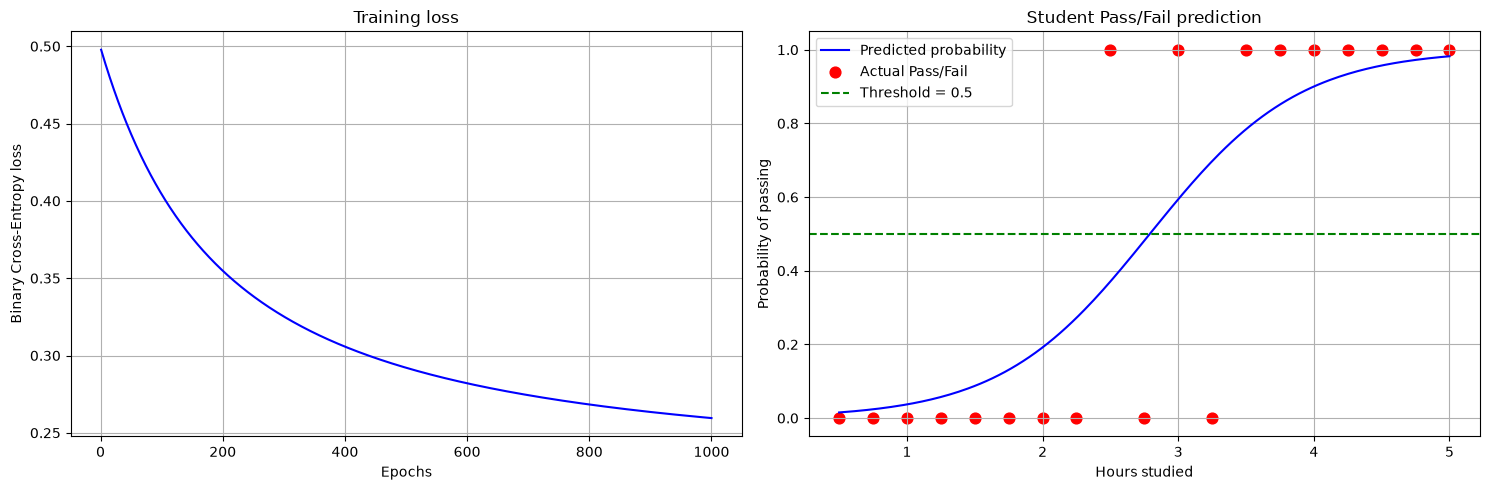

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Training loss
axes[0].plot(range(1, epochs + 1), loss_history, color="blue")
axes[0].set_xlabel("Epochs"); axes[0].set_ylabel("Binary Cross-Entropy loss")
axes[0].set_title("Training loss"); axes[0].grid(True)

# (b) Sigmoid curve vs. data
X_curve = np.linspace(X.min(), X.max(), 200)
axes[1].plot(X_curve, sigmoid(w * X_curve + b), color="blue", label="Predicted probability")
axes[1].scatter(X, y, color="red", s=60, label="Actual Pass/Fail")
axes[1].axhline(0.5, color="green", linestyle="--", label="Threshold = 0.5")
axes[1].set_xlabel("Hours studied"); axes[1].set_ylabel("Probability of passing")
axes[1].set_title("Student Pass/Fail prediction"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout(); plt.show()

## 5. Three Code-Related Talking Points

### 1. How my code predicts whether a student will pass or fail (Sections 4.1, 4.2 and 4.4)

I built a logistic regression model from scratch with NumPy. The study hours are in `X` and the results in `y` (1 = Pass, 0 = Fail). The code first calculates a linear score `z = w * X + b`, where `w` is the weight (how strongly study hours affect the score) and `b` is the bias (a baseline shift). It passes `z` through the sigmoid function, which squeezes it into a probability between 0 and 1; for example, 0.8 means an estimated 80% chance of passing. Finally, `(probabilities >= 0.5).astype(int)` turns the probabilities into predictions: 0.5 or higher is Pass, otherwise Fail, and `.astype(int)` converts the `True/False` comparison into `1/0`.

### 2. How the model learns using loss and gradient descent (Sections 1, 4.3)

The model starts from `w = 0.5` and `b = -1`. **Binary Cross-Entropy** measures how far the predicted probabilities are from the real labels: lower is better, and confident mistakes are penalized heavily. `np.clip` keeps probabilities away from exactly 0 and 1 to avoid `log(0)`. In every epoch, gradient descent computes `dw` and `db`, which say how the loss changes when `w` and `b` change (the gradient of the loss is simply `p - y`, multiplied by `x` for the weight), then updates `w = w - learning_rate * dw` and `b = b - learning_rate * db`. I repeat this for 1,000 epochs with a learning rate of 0.1 and store each epoch's loss in `loss_history` so that I can plot it.

### 3. How the model's performance is checked and visualized (Sections 4.4 and 4.5)

After training, the final `w` and `b` give a probability and a Pass/Fail prediction for every student. Accuracy is `np.mean(predictions == y) * 100`, reported with the counts of correct and incorrect predictions. Two plots support the evaluation: (a) the training loss per epoch, which should fall as the model fits, and (b) the sigmoid curve of predicted probability against study hours, with the actual labels as red points and the 0.5 threshold as a green dashed line. **Limitation:** the same data is used for training and for evaluation, so accuracy only describes performance on examples the model has already seen; with 19 students, a train/test split or cross-validation would be needed for a fair estimate on new students.